# **Avaliação da qualidade de vinhos tintos com o uso de Machine Learning**

A análise será conduzida com base em um conjunto de dados que inclui informações sobre diversas características físico-químicas dos vinhos, como acidez, teor alcoólico, densidade e pH.

Primeiramente, será realizada uma **análise exploratória** para entender a estrutura e o padrão dos dados. Posteriormente, os modelos **Árvore de Decisão** e **Floresta Aleatória** serão utilizados para classificar os vinhos em duas faixas de qualidade: Baixa e Média/Alta.

In [41]:
!pip install -q scikit-learn==1.7.2

In [42]:
#Importando as bibliotecas necessárias para análise e modelos

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score
)

In [43]:
#Importando o banco de dados dos vinhos

from google.colab import files

arquivo = files.upload()

Saving winequality-red.csv to winequality-red (1).csv


In [44]:
#Lendo o arquivo e armazenando em 'dados'

dados = pd.read_csv('winequality-red.csv', sep=';')

In [45]:
#Mostra as 5 primeiras linhas

dados.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [46]:
#Dimensão da base de dados

dados.shape

(1599, 12)

In [47]:
#Resumo da estrutura

dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [48]:
#Verificando a existência de valores ausentes em cada coluna

dados.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [49]:
#Confirma que não se tem valores ausentes e podemos progredir

dados.isnull().sum().sum()

np.int64(0)

In [50]:
#Verifica quantas linhas estão duplicadas, mas o resultado não significa necessariamente que devemos excluir

dados.duplicated().sum()

np.int64(240)

In [51]:
#Ajuda a entender se os repetidos são completamente iguais

duplicados = dados[dados.duplicated(keep=False)]

duplicados.head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
9,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5
11,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5
22,7.9,0.430,0.21,1.60,0.106,10.0,37.0,0.9966,3.17,0.91,9.5,5
27,7.9,0.430,0.21,1.60,0.106,10.0,37.0,0.9966,3.17,0.91,9.5,5
39,7.3,0.450,0.36,5.90,0.074,12.0,87.0,0.9978,3.33,0.83,10.5,5
40,7.3,0.450,0.36,5.90,0.074,12.0,87.0,0.9978,3.33,0.83,10.5,5
64,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.9962,3.41,0.39,10.9,5
65,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.9962,3.41,0.39,10.9,5


In [52]:
#Agrupa os vinhos que possuem exatamente as mesmas 11 características físico-químicas

variaveis = dados.drop(columns=['quality']).columns

repetidos = dados.groupby(list(variaveis)).agg(
    quantidade=('quality', 'size'),
    notas_diferentes=('quality', 'nunique')
)

print("Combinações repetidas:")
print((repetidos['quantidade'] > 1).sum())

print("\nCombinações com notas diferentes:")
print((repetidos['notas_diferentes'] > 1).sum())

print("\nMaior quantidade de repetições:")
print(repetidos['quantidade'].max())

Combinações repetidas:
220

Combinações com notas diferentes:
0

Maior quantidade de repetições:
4


In [53]:
#resumo estatístico das variáveis numéricas

dados.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


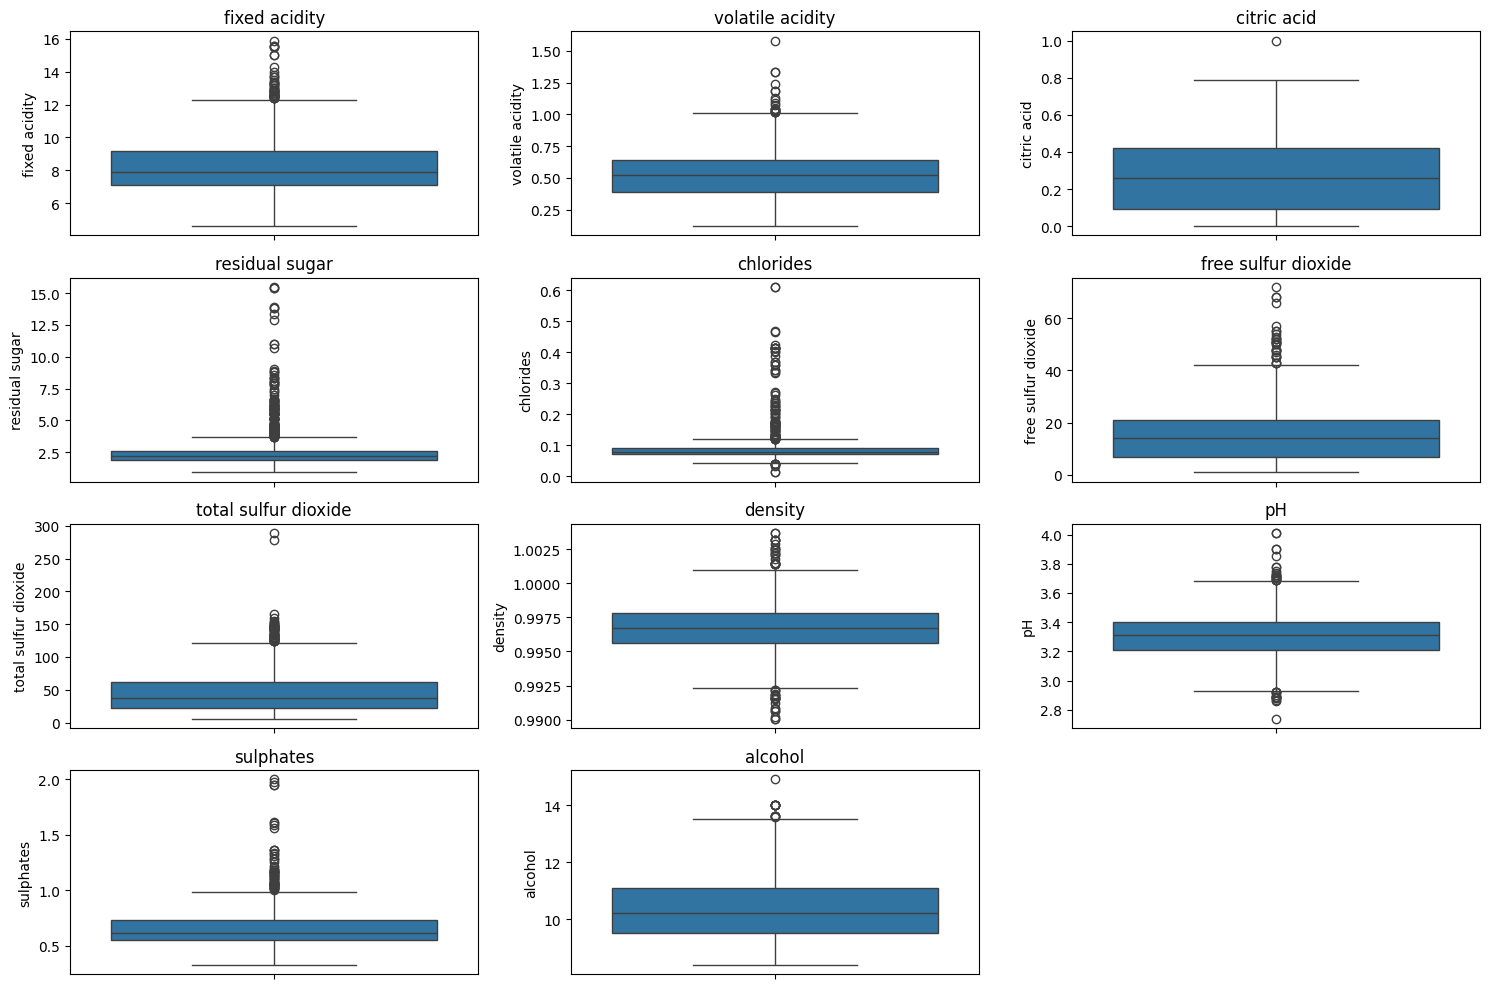

In [54]:
#boxplots

plt.figure(figsize=(15, 10))

variaveis = dados.drop(columns=['quality']).columns

for i, coluna in enumerate(variaveis):
    plt.subplot(4, 3, i + 1)
    sns.boxplot(y=dados[coluna])
    plt.title(coluna)

plt.tight_layout()
plt.show()

In [55]:
#investigação quantitativa - características apresentam maior quantidade de valores atípicos

variaveis = dados.drop(columns=['quality']).columns

resultados = []

for coluna in variaveis:
    Q1 = dados[coluna].quantile(0.25)
    Q3 = dados[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    quantidade = ((dados[coluna] < limite_inferior) |
                  (dados[coluna] > limite_superior)).sum()

    resultados.append([coluna, limite_inferior,
                       limite_superior, quantidade])

tabela_outliers = pd.DataFrame(
    resultados,
    columns=['Variavel', 'Limite inferior',
             'Limite superior', 'Quantidade de outliers']
)

tabela_outliers

,Variavel,Limite inferior,Limite superior,Quantidade de outliers
0,fixed acidity,3.950000,12.350000,49
1,volatile acidity,0.015000,1.015000,19
2,citric acid,-0.405000,0.915000,1
3,residual sugar,0.850000,3.650000,155
4,chlorides,0.040000,0.120000,112
5,free sulfur dioxide,-14.000000,42.000000,30
6,total sulfur dioxide,-38.000000,122.000000,55
7,density,0.992248,1.001187,45
8,pH,2.925000,3.685000,35
9,sulphates,0.280000,1.000000,59


In [56]:
print("MAIORES VALORES DE AÇÚCAR RESIDUAL")
print(dados.nlargest(10, 'residual sugar')[
    ['residual sugar', 'quality']
])

print("\nMAIORES VALORES DE CLORETOS")
print(dados.nlargest(10, 'chlorides')[
    ['chlorides', 'quality']
])

MAIORES VALORES DE AÇÚCAR RESIDUAL
      residual sugar  quality
480             15.5        5
1434            15.4        6
1435            15.4        6
1574            13.9        6
1474            13.8        5
1476            13.8        5
1244            13.4        6
1235            12.9        4
324             11.0        6
325             11.0        6

MAIORES VALORES DE CLORETOS
      chlorides  quality
258       0.611        5
151       0.610        4
106       0.467        5
81        0.464        5
692       0.422        5
754       0.415        6
1370      0.415        5
1372      0.415        5
1051      0.414        5
1319      0.414        6


In [57]:
#Distribuição das qualidades

dados['quality'].value_counts().sort_index()

,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


In [58]:
#Percentual

dados['quality'].value_counts(
    normalize=True
).sort_index() * 100

,proportion
quality,
3,0.625391
4,3.314572
5,42.589118
6,39.899937
7,12.445278
8,1.125704


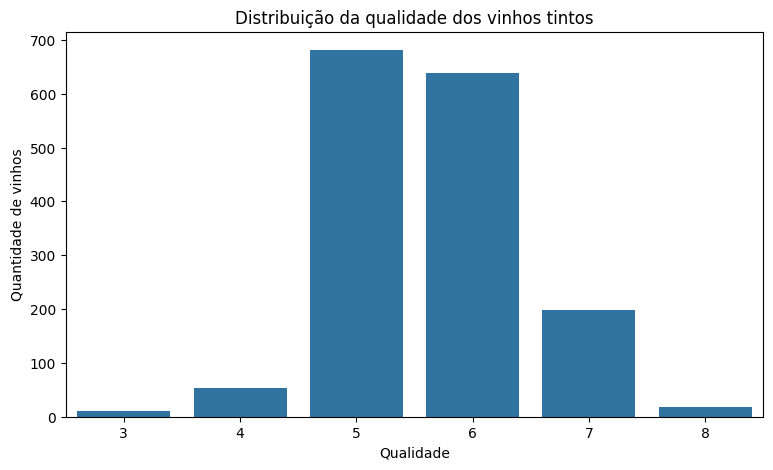

In [59]:
#Gráfico

plt.figure(figsize=(9, 5))

sns.countplot(
    data=dados,
    x='quality'
)

plt.title('Distribuição da qualidade dos vinhos tintos')
plt.xlabel('Qualidade')
plt.ylabel('Quantidade de vinhos')

plt.show()

In [60]:
#análise de correlação entre as variáveis

correlacao = dados.corr()
correlacao

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397


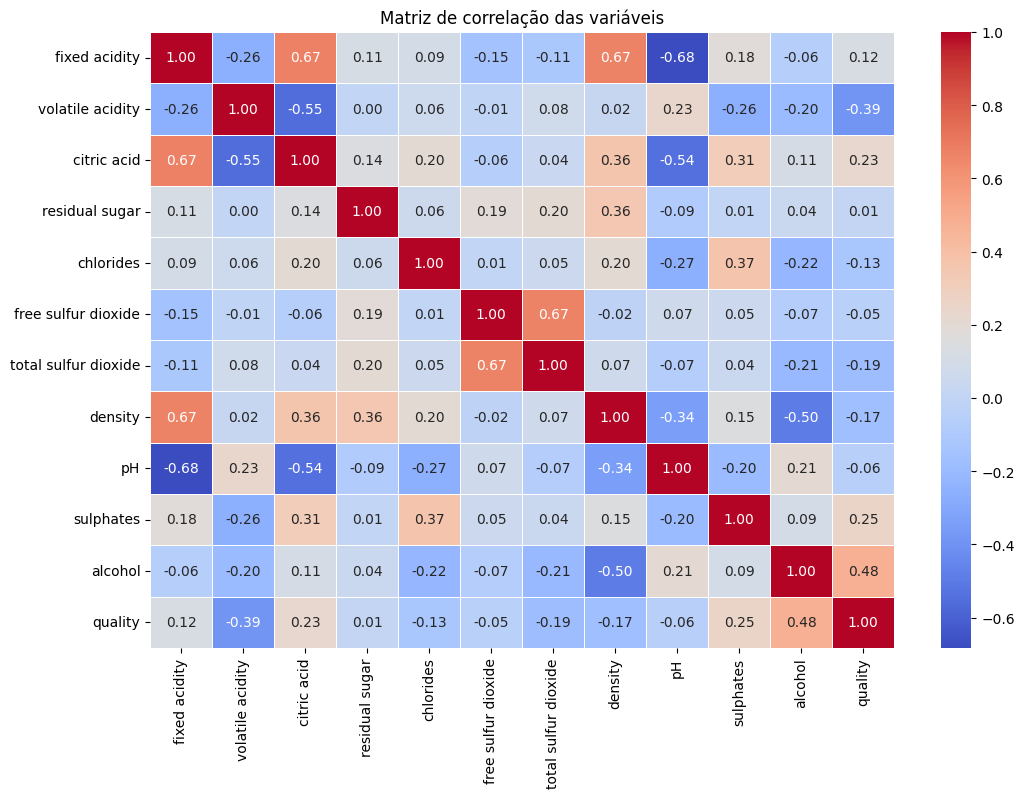

In [61]:
#Representação visual - mapa de calor

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlacao,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Matriz de correlação das variáveis')
plt.show()

In [62]:
#Correlação das variáveis com a 'quality'

correlacao['quality'].sort_values(
    ascending=False
)

,quality
quality,1.000000
alcohol,0.476166
sulphates,0.251397
citric acid,0.226373
fixed acidity,0.124052
residual sugar,0.013732
free sulfur dioxide,-0.050656
pH,-0.057731
chlorides,-0.128907
density,-0.174919


# **Machine Learning com duas classes**

A variável `quality`, que inicialmente possuía seis categorias (notas de 3 a 8), foi reclassificada em duas categorias: **Baixa** (notas 3, 4 e 5) e **Média/Alta** (notas 6, 7 e 8).

Essa divisão foi adotada como uma opção metodológica para tornar o problema de classificação mais simples e criar grupos com um número de observações relativamente equilibrado. Assim, a classe Baixa abrange 744 vinhos (46,53%), ao passo que a classe Média/Alta engloba 855 vinhos (53,47%).

Com base nessa transformação, foram criados dois modelos de classificação: Árvore de Decisão (Decision Tree) e Floresta Aleatória (Random Forest). Métricas de classificação foram usadas para avaliar o desempenho dos modelos, o que possibilitou a comparação de seus resultados.

In [63]:
#X = explicativas e Y = respostas, e estamos criando as duas classes para separar e poder analisar

X = dados.drop(columns=['quality'])
y = dados['quality']

y_binario = y.map(
    lambda qualidade: 'Baixa' if qualidade <= 5 else 'Media/Alta'
)

print("Dimensões das variáveis explicativas:", X.shape)
print("Dimensões da variável resposta:", y_binario.shape)

Dimensões das variáveis explicativas: (1599, 11)
Dimensões da variável resposta: (1599,)


In [64]:
print("Distribuição das novas classes:")
print(y_binario.value_counts())

print("\nPercentual de cada classe:")
print(y_binario.value_counts(normalize=True) * 100)

Distribuição das novas classes:
quality
Media/Alta    855
Baixa         744
Name: count, dtype: int64

Percentual de cada classe:
quality
Media/Alta    53.470919
Baixa         46.529081
Name: proportion, dtype: float64


In [65]:
# Identificar grupos de registros com características iguais
grupos = X.groupby(list(X.columns), sort=False).ngroup()

# Criar a divisão dos dados
divisao = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Separar os índices de treinamento e teste
indices_treino, indices_teste = next(
    divisao.split(X, y_binario, groups=grupos)
)

# Criar os conjuntos de treinamento e teste
X_treino = X.iloc[indices_treino]
X_teste = X.iloc[indices_teste]

y_treino = y_binario.iloc[indices_treino]
y_teste = y_binario.iloc[indices_teste]

print("Dimensões do treinamento:", X_treino.shape)
print("Dimensões do teste:", X_teste.shape)

print("\nDistribuição no treinamento:")
print(y_treino.value_counts())

print("\nDistribuição no teste:")
print(y_teste.value_counts())

Dimensões do treinamento: (1281, 11)
Dimensões do teste: (318, 11)

Distribuição no treinamento:
quality
Media/Alta    681
Baixa         600
Name: count, dtype: int64

Distribuição no teste:
quality
Media/Alta    174
Baixa         144
Name: count, dtype: int64


In [66]:
#Criação da primeira árvore e balanceamento das classes

arvore = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

In [67]:
#Treinamento da árvore

arvore.fit(X_treino, y_treino)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [68]:
#Previsões da árvore

previsoes_arvore = arvore.predict(X_teste)

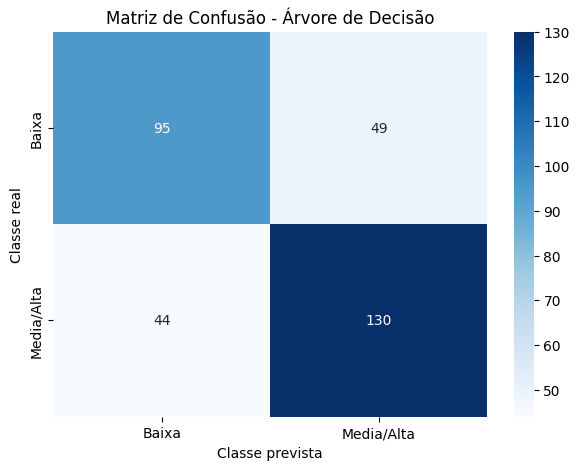

In [69]:
#Gerando a matriz de confusão

matriz = confusion_matrix(
    y_teste,
    previsoes_arvore,
    labels=['Baixa', 'Media/Alta']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Baixa', 'Media/Alta'],
    yticklabels=['Baixa', 'Media/Alta']
)

plt.xlabel('Classe prevista')
plt.ylabel('Classe real')
plt.title('Matriz de Confusão - Árvore de Decisão')

plt.show()

Métricas por classe:


,precision,recall,f1-score
Baixa,0.68,0.66,0.67
Media/Alta,0.73,0.75,0.74


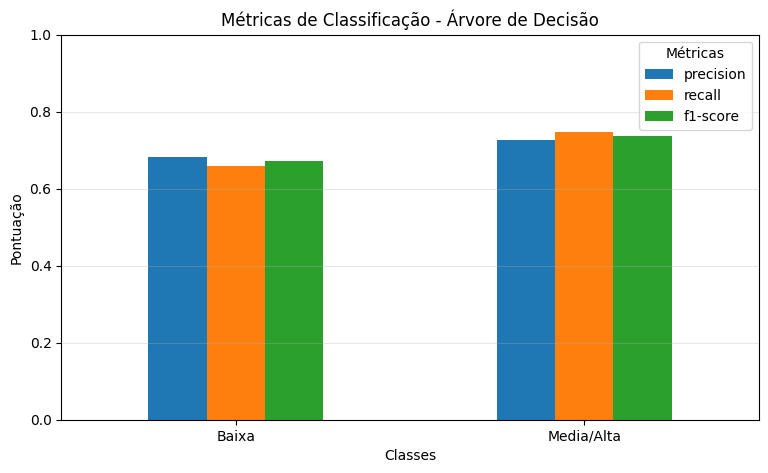

In [70]:
relatorio = classification_report(
    y_teste,
    previsoes_arvore,
    labels=['Baixa', 'Media/Alta'],
    output_dict=True
)

metricas = pd.DataFrame(relatorio).T

metricas_classes = metricas.loc[
    ['Baixa', 'Media/Alta'],
    ['precision', 'recall', 'f1-score']
]

print("Métricas por classe:")
display(metricas_classes.round(2))

metricas_classes.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Métricas de Classificação - Árvore de Decisão')
plt.xlabel('Classes')
plt.ylabel('Pontuação')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Métricas')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [71]:
acuracia = accuracy_score(y_teste, previsoes_arvore)

acuracia_balanceada = balanced_accuracy_score(
    y_teste,
    previsoes_arvore
)

kappa = cohen_kappa_score(
    y_teste,
    previsoes_arvore
)

f1_macro = metricas.loc['macro avg', 'f1-score']

resultados_arvore = pd.DataFrame({
    'Métrica': [
        'Acurácia',
        'Acurácia balanceada',
        'F1-score macro',
        'Coeficiente Kappa'
    ],
    'Resultado': [
        acuracia,
        acuracia_balanceada,
        f1_macro,
        kappa
    ]
})

display(resultados_arvore.round(4))

,Métrica,Resultado
0,Acurácia,0.7075
1,Acurácia balanceada,0.7034
2,F1-score macro,0.7040
3,Coeficiente Kappa,0.4081


In [72]:
#Criando a floresta e balanceando

floresta = RandomForestClassifier(
    n_estimators=100,
    max_depth=3,
    min_samples_split=2,
    class_weight='balanced',
    random_state=42
)

In [73]:
#Treinamento da floresta

floresta.fit(X_treino, y_treino)

,n_estimators,100
,criterion,'gini'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [74]:
#Previsões

previsoes_floresta = floresta.predict(X_teste)

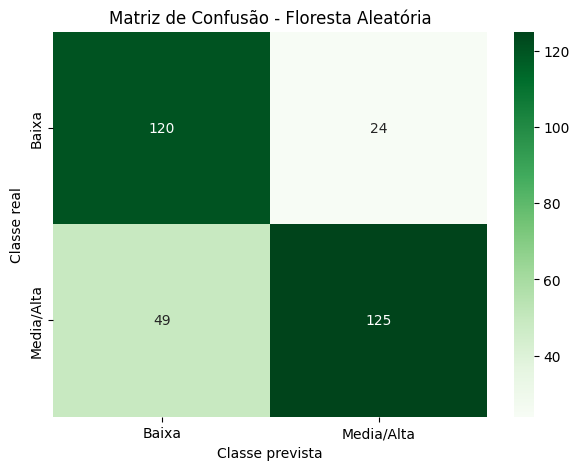

In [75]:
#Criando a matriz de confusão

matriz_floresta = confusion_matrix(
    y_teste,
    previsoes_floresta,
    labels=['Baixa', 'Media/Alta']
)

plt.figure(figsize=(7,5))

sns.heatmap(
    matriz_floresta,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Baixa', 'Media/Alta'],
    yticklabels=['Baixa', 'Media/Alta']
)

plt.xlabel('Classe prevista')
plt.ylabel('Classe real')
plt.title('Matriz de Confusão - Floresta Aleatória')

plt.show()

Métricas por classe:


,precision,recall,f1-score
Baixa,0.71,0.83,0.77
Media/Alta,0.84,0.72,0.77


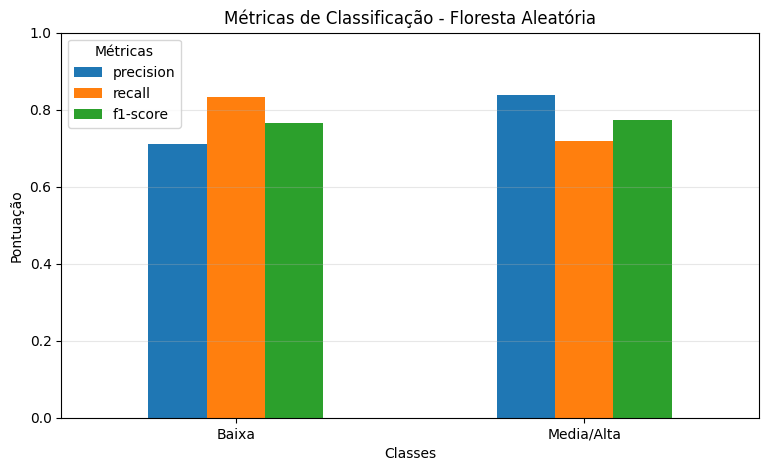

In [76]:
relatorio_floresta = classification_report(
    y_teste,
    previsoes_floresta,
    labels=['Baixa', 'Media/Alta'],
    output_dict=True
)

metricas_floresta = pd.DataFrame(relatorio_floresta).T

metricas_classes_floresta = metricas_floresta.loc[
    ['Baixa', 'Media/Alta'],
    ['precision', 'recall', 'f1-score']
]

print("Métricas por classe:")
display(metricas_classes_floresta.round(2))

metricas_classes_floresta.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Métricas de Classificação - Floresta Aleatória')
plt.xlabel('Classes')
plt.ylabel('Pontuação')
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(title='Métricas')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [77]:
acuracia_floresta = accuracy_score(
    y_teste,
    previsoes_floresta
)

acuracia_balanceada_floresta = balanced_accuracy_score(
    y_teste,
    previsoes_floresta
)

kappa_floresta = cohen_kappa_score(
    y_teste,
    previsoes_floresta
)

f1_macro_floresta = metricas_floresta.loc[
    'macro avg',
    'f1-score'
]

resultados_floresta = pd.DataFrame({
    'Métrica': [
        'Acurácia',
        'Acurácia balanceada',
        'F1-score macro',
        'Coeficiente Kappa'
    ],
    'Resultado': [
        acuracia_floresta,
        acuracia_balanceada_floresta,
        f1_macro_floresta,
        kappa_floresta
    ]
})

display(resultados_floresta.round(4))

,Métrica,Resultado
0,Acurácia,0.7704
1,Acurácia balanceada,0.7759
2,F1-score macro,0.7704
3,Coeficiente Kappa,0.5436


Comparação dos modelos:


,Árvore de Decisão,Floresta Aleatória
Acurácia,0.7075,0.7704
Acurácia balanceada,0.7034,0.7759
F1-score macro,0.7040,0.7704
Kappa,0.4081,0.5436


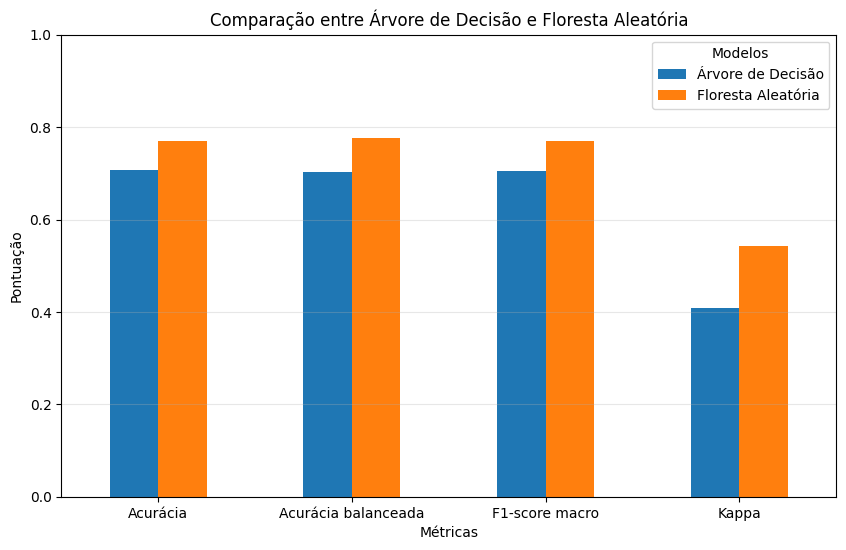

In [78]:
#Comparação entre os dois modelos

comparacao = pd.DataFrame({
    'Árvore de Decisão': [
        acuracia,
        acuracia_balanceada,
        f1_macro,
        kappa
    ],
    'Floresta Aleatória': [
        acuracia_floresta,
        acuracia_balanceada_floresta,
        f1_macro_floresta,
        kappa_floresta
    ]
}, index=[
    'Acurácia',
    'Acurácia balanceada',
    'F1-score macro',
    'Kappa'
])

print("Comparação dos modelos:")
display(comparacao.round(4))

comparacao.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Comparação entre Árvore de Decisão e Floresta Aleatória')
plt.xlabel('Métricas')
plt.ylabel('Pontuação')
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(title='Modelos')
plt.grid(axis='y', alpha=0.3)
plt.show()

# **Resultado da comparação dos modelos**

A análise dos resultados revelou que o modelo de Floresta Aleatória teve um desempenho melhor em comparação ao modelo de Árvore de Decisão em todas as métricas analisadas.

A taxa de acurácia da Floresta Aleatória foi de 77,04%, enquanto a Árvore de Decisão atingiu 70,75%. A acurácia balanceada também foi mais alta, subindo de 70,34% para 77,59%. O mesmo padrão foi observado no F1-score macro, com resultados de 77,04% e 70,40%, respectivamente.

Adicionalmente, o coeficiente Kappa da Floresta Aleatória foi de 0,5436, enquanto o da Árvore de Decisão foi de 0,4081, sugerindo uma maior concordância entre as previsões realizadas pelo modelo e os valores reais.

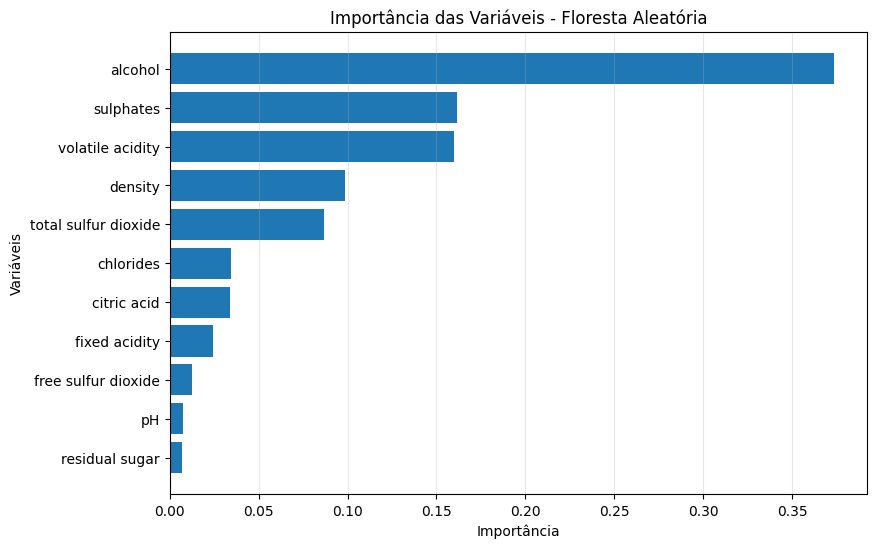

In [79]:
#importância de cada variável na Floresta Aleatória

importancias = pd.DataFrame({
    'Variavel': X.columns,
    'Importancia': floresta.feature_importances_
})

importancias = importancias.sort_values(
    by='Importancia',
    ascending=True
)

plt.figure(figsize=(9,6))

plt.barh(
    importancias['Variavel'],
    importancias['Importancia']
)

plt.title('Importância das Variáveis - Floresta Aleatória')
plt.xlabel('Importância')
plt.ylabel('Variáveis')

plt.grid(axis='x', alpha=0.3)
plt.show()

# **Importancia das variáveis**

Conforme a análise do modelo de Floresta Aleatória, o teor alcoólico (alcohol) liderou a importância das variáveis (≈ 0,3735), seguido por sulphates (0,1617), volatile acidity (0,1600), density (0,0984) e total sulfur dioxide (0,0870).

Embora esses fatores tenham dominado o processo de classificação, é importante destacar que a importância das variáveis mede apenas a contribuição algorítmica, sem implicar uma relação de causa e efeito sobre a qualidade dos vinhos.

In [80]:
importancias = importancias.sort_values(
    by='Importancia',
    ascending=False
)

display(importancias.round(4))

,Variavel,Importancia
10,alcohol,0.3735
9,sulphates,0.1617
1,volatile acidity,0.1600
7,density,0.0984
6,total sulfur dioxide,0.0870
4,chlorides,0.0345
2,citric acid,0.0340
0,fixed acidity,0.0241
5,free sulfur dioxide,0.0124
8,pH,0.0075
